# CSCI E-89: Problem Set 05

Schwartzberg, Paul

This notebook contains all four HW5 solutions. Each problem includes its code, results and explanation. The accompanying HTML file is an export of this notebook.

1. [Tiger image transformations](#problem-1)
2. [Batch normalisation and augmentation](#problem-2)
3. [VGG16 flower classification](#problem-3)
4. [Grad-CAM](#problem-4)

Use the **cscie89** kernel. Restart the kernel and run the notebook from top to bottom. Later sections reuse some variable names. The full run trains four CNN conditions and both VGG16 stages; allow roughly half an hour on this CPU. Validation loss selects checkpoints. All final flower test metrics use the full 551-image test split.

The source tiger image is included. Flower Photos and ImageNet VGG16 weights are downloaded when missing. The code recreates the trained checkpoints before using them for Grad-CAM. All solution definitions are included here.


<a id="problem-1"></a>

## Problem 1: Five tiger image transformations

This notebook applies the five transformations requested in Problem 1. Each starts from the same photograph, so the effects can be compared separately. Each transformation uses `torchvision.transforms.Compose`.

The phrase **around an axis** means reflection about that axis. Reflection about a horizontal axis swaps top and bottom; reflection about a vertical axis swaps left and right. Torchvision names its flips by the direction in which the pixels move, so `RandomVerticalFlip` performs the horizontal-axis reflection and `RandomHorizontalFlip` performs the vertical-axis reflection.

Use the **cscie89** kernel. Problem 1 runs on the CPU and needs no trained model.

### 1.1 Set up the tools and output folder

`Path` handles file locations. Pillow opens and resamples images. NumPy handles the diagonal stretch calculation. Matplotlib draws the results. Torchvision supplies `Compose`, flips, rotation and tensor conversion. The printed Python path identifies the environment running this notebook.

In [1]:
# Import the tools used below and show the active Python environment.
from pathlib import Path
from urllib.request import Request, urlopen
from io import BytesIO
import json
import sys

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode

ASSET_DIR = Path("assets")
OUTPUT_DIR = Path("outputs/problem1")
ASSET_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)


Python: C:\Users\schwa\.conda\envs\cscie89\python.exe
PyTorch: 2.14.0+cpu | torchvision: 0.29.0+cpu


### 1.2 Load a photograph at moderate resolution

The photograph shows a Bengal tiger. <br><br>It is credited to John and Karen Hollingsworth of the U.S. Fish and Wildlife Service and is listed as public domain in the United States on its [Wikimedia Commons source page](https://commons.wikimedia.org/wiki/File:Panthera_tigris_tigris_original.jpg).

The saved copy is 960 x 641 pixels. <br><br>This keeps the proportions of the source while giving enough detail for the demonstration. <br>The repository includes this copy; the download runs only if it is missing. <br>The code converts it to RGB, meaning red, green and blue colour channels.

In [2]:
# Use the saved photograph. Download it only if the local copy is missing.
TIGER_PAGE = "https://commons.wikimedia.org/wiki/File:Panthera_tigris_tigris_original.jpg"
TIGER_URL = "https://upload.wikimedia.org/wikipedia/commons/f/f9/Panthera_tigris_tigris_original.jpg"
TIGER_PATH = ASSET_DIR / "tiger.jpg"
if not TIGER_PATH.exists():
    request = Request(TIGER_URL, headers={"User-Agent": "CSCI-E89-HW5/1.0 (educational image transformations)"})
    with urlopen(request, timeout=45) as response:
        downloaded = response.read()
    with Image.open(BytesIO(downloaded)) as picture:
        picture = picture.convert("RGB")
        picture.thumbnail((960, 960))  # Keep the aspect ratio; limit the longest side.
        picture.save(TIGER_PATH, quality=92)

with Image.open(TIGER_PATH) as picture:
    tiger = picture.convert("RGB")
print("Working image:", TIGER_PATH, "| width x height:", tiger.size)


Working image: assets\tiger.jpg | width x height: (960, 641)


### 1.3 Define a 10% stretch along one diagonal

We choose the line from the image's top-left corner to its bottom-right corner. <br>The stretch lengthens distances parallel to that line by 10%, while leaving distances perpendicular to it unchanged. It acts about the image centre.

The diagonal stretch needs a small custom transformation. <br>`Compose` accepts a callable object: its `__call__` method receives an image and returns a transformed image. <br>The calculation below finds the diagonal direction, builds the stretch, enlarges the canvas to hold the result, and samples the source image.

For the numerical calculation, `u` is a unit vector along the diagonal. <br>The matrix is `A = I + 0.10 * outer(u, u)`. <br>It gives `A @ u = 1.10 * u` and leaves a perpendicular vector unchanged. <br>Pillow uses the inverse matrix because it works backwards from each output pixel to the corresponding source position. <br>Bilinear interpolation estimates values between source pixels; the new border is white.

In [3]:
class DiagonalStretch:
    """Stretch along the image's top-left to bottom-right diagonal about its centre."""

    def __init__(self, factor=1.10, fill=(255, 255, 255)):
        self.factor = float(factor)
        self.fill = fill
        if self.factor < 1:
            raise ValueError("This demonstration expects a stretch factor of at least one.")

    def __call__(self, image):
        width, height = image.size
        # A unit vector gives the diagonal's direction, including a non-square image.
        diagonal = np.array([width, height], dtype=float)
        diagonal /= np.linalg.norm(diagonal)
        # Add 10% only to the component parallel to that diagonal.
        forward = np.eye(2) + (self.factor - 1) * np.outer(diagonal, diagonal)
        # Positive entries let us find the bounding canvas from width and height.
        out_width, out_height = np.ceil(forward @ [width, height]).astype(int)
        original_centre = np.array([width, height], dtype=float) / 2
        output_centre = np.array([out_width, out_height], dtype=float) / 2
        # Pillow needs the reverse mapping: for each output pixel, where to sample.
        inverse = np.linalg.inv(forward)
        offset = original_centre - inverse @ output_centre
        coefficients = (
            inverse[0, 0], inverse[0, 1], offset[0],
            inverse[1, 0], inverse[1, 1], offset[1],
        )
        return image.transform(
            (int(out_width), int(out_height)), Image.Transform.AFFINE,
            coefficients, resample=Image.Resampling.BILINEAR, fillcolor=self.fill,
        )


### 1.4 Build five separate Compose pipelines

Each pipeline first changes the photograph, then calls `ToTensor`. For an RGB image, `ToTensor` stores three channels, puts channels before height and width, and scales pixel values from 0-255 to 0-1.

Setting the flip probability to `1.0` makes the change happen every time. <br>A rotation interval such as `(10, 10)` fixes the angle at 10 degrees. <br>Positive rotation angles turn left (counter-clockwise); negative angles turn right (clockwise). `expand=True` enlarges the canvas to keep the rotated corners. <br>The white border fills space outside the transformed photograph.

The five operations are separate. <br>Applying all five in one pipeline would produce one combined transformation and hide their individual effects. <br>See the [Compose documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Compose.html) <br>and [rotation documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.functional.rotate.html).

In [4]:
# Each Compose starts from the same photograph and ends with tensor conversion.
# p=1 forces the flips to happen; equal rotation bounds fix the angle.
tiger_transforms = {
    "horizontal_axis_flip": transforms.Compose([
        transforms.RandomVerticalFlip(p=1.0),  # Reflection about a horizontal axis.
        transforms.ToTensor(),
    ]),
    "vertical_axis_flip": transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),  # Reflection about a vertical axis.
        transforms.ToTensor(),
    ]),
    "diagonal_stretch_10_percent": transforms.Compose([
        DiagonalStretch(factor=1.10),
        transforms.ToTensor(),
    ]),
    "rotate_left_10_degrees": transforms.Compose([
        transforms.RandomRotation((10, 10), interpolation=InterpolationMode.BILINEAR,
                                  expand=True, fill=255),
        transforms.ToTensor(),
    ]),
    "rotate_right_15_degrees": transforms.Compose([
        transforms.RandomRotation((-15, -15), interpolation=InterpolationMode.BILINEAR,
                                  expand=True, fill=255),
        transforms.ToTensor(),
    ]),
}
# Each tensor has shape (three colour channels, height, width), with values in [0, 1].
tiger_results = {name: pipeline(tiger) for name, pipeline in tiger_transforms.items()}


### 1.5 Check the diagonal scale

This short calculation checks the geometry. <br>A unit length along the chosen diagonal becomes 1.10 units; a unit length perpendicular to it stays 1.00 units. <br>Image interpolation can alter individual pixel values, but it does not change the intended geometric scale.

In [5]:
# Check the mathematical meaning of the stretch independently of the photograph.
u = np.array(tiger.size, dtype=float)
u /= np.linalg.norm(u)
v = np.array([-u[1], u[0]])  # A unit direction perpendicular to the chosen diagonal.
A = np.eye(2) + 0.10 * np.outer(u, u)
print(f"Length scale along the diagonal: {np.linalg.norm(A @ u):.2f}")
print(f"Length scale across the diagonal: {np.linalg.norm(A @ v):.2f}")
print("These are the geometric scales before resampling pixels.")


Length scale along the diagonal: 1.10
Length scale across the diagonal: 1.00
These are the geometric scales before resampling pixels.


### 1.6 Display and save the results

The figure shows the original and five transformed versions.<br>`permute(1, 2, 0)` <br>places the tensor dimensions in the order Matplotlib needs: <br>height, width, channels. <br>The titles state the operation and output size. We save each transformed PNG, the comparison figure and a JSON record of the settings.

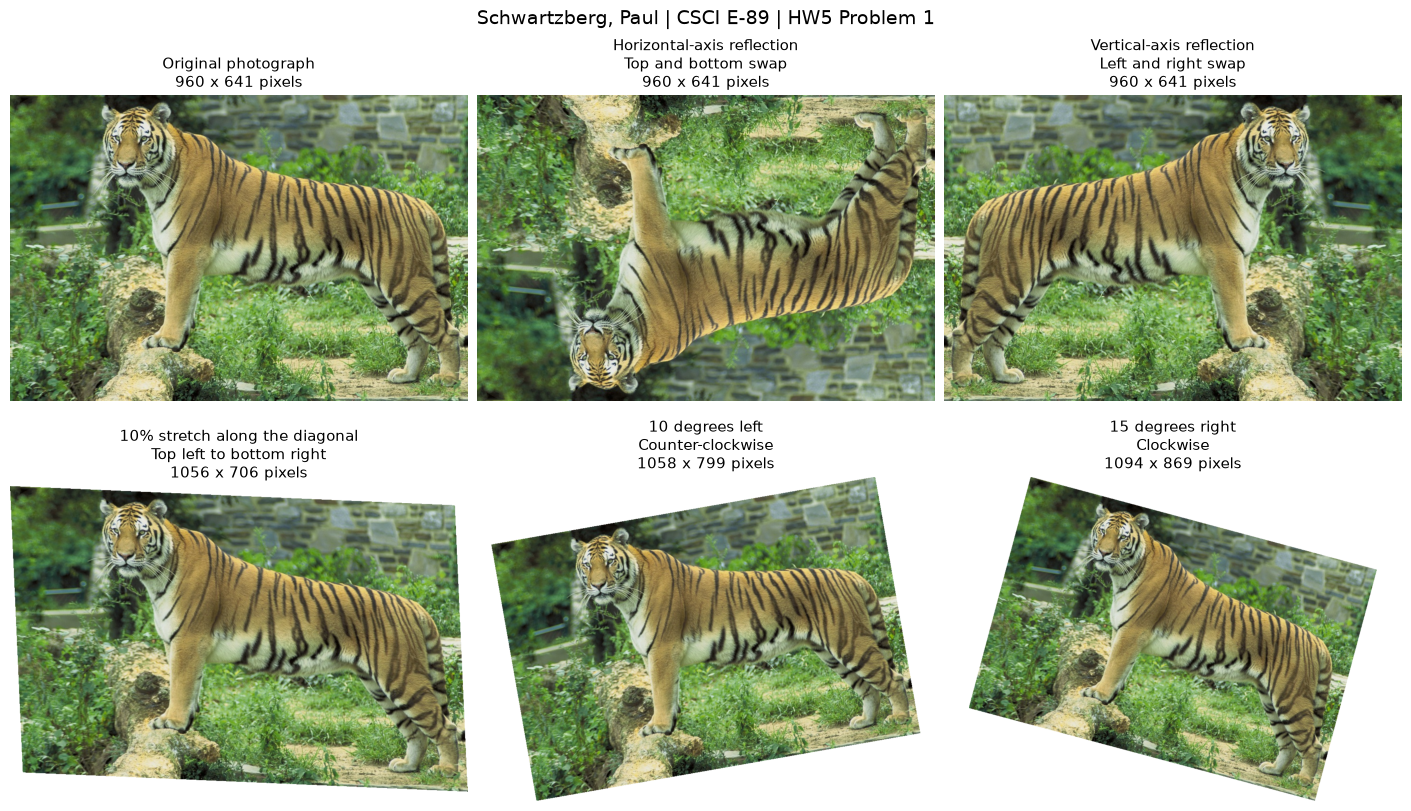

Saved the five transformed images, comparison plot and transformation record in outputs\problem1


In [6]:
# Display the original and five separate results; save a static report and images.
labels = {
    "horizontal_axis_flip": "Horizontal-axis reflection\nTop and bottom swap",
    "vertical_axis_flip": "Vertical-axis reflection\nLeft and right swap",
    "diagonal_stretch_10_percent": "10% stretch along the diagonal\nTop left to bottom right",
    "rotate_left_10_degrees": "10 degrees left\nCounter-clockwise",
    "rotate_right_15_degrees": "15 degrees right\nClockwise",
}
shown = {"original": transforms.ToTensor()(tiger), **tiger_results}
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
manifest = {"author": "Schwartzberg, Paul", "source_page": TIGER_PAGE,
            "source_url": TIGER_URL, "image_credit": "John and Karen Hollingsworth, U.S. Fish and Wildlife Service; public domain in the United States",
            "stretch_factor": 1.10, "results": {}}
for ax, (name, tensor) in zip(axes.flat, shown.items()):
    # Matplotlib expects height, width, channels; tensors store channels first.
    ax.imshow(tensor.permute(1, 2, 0).numpy())
    title = "Original photograph" if name == "original" else labels[name]
    ax.set_title(f"{title}\n{tensor.shape[2]} x {tensor.shape[1]} pixels", fontsize=11)
    ax.axis("off")
    if name != "original":
        transforms.ToPILImage()(tensor).save(OUTPUT_DIR / f"{name}.png")
    manifest["results"][name] = {"tensor_shape": list(tensor.shape), "width": tensor.shape[2], "height": tensor.shape[1]}
fig.suptitle("Schwartzberg, Paul | CSCI E-89 | HW5 Problem 1", fontsize=14)
fig.savefig(OUTPUT_DIR / "tiger_transformations.png", dpi=120)
plt.show()
(OUTPUT_DIR / "transformations.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved the five transformed images, comparison plot and transformation record in", OUTPUT_DIR)


### Observations

The horizontal-axis reflection puts the tiger upside down. The vertical-axis reflection moves its head to the other side. The diagonal stretch changes the tiger's proportions slightly along the chosen diagonal. The two rotations tilt the photograph by the requested angles; their canvases grow to keep the full photograph.

These examples show how image transformations change orientation and shape. Their suitability as training augmentation depends on the task: an upside-down tiger is useful for showing a flip, but may be uncommon in the images a classifier will receive.

**Problem 1 is complete.** The code, source image, five transformations, comparison figure and HTML export are saved with this solution. The following sections contain Problems 2-4.

<a id="problem-2"></a>

## Problem 2: Batch normalisation and augmentation

We adapt the three-block `BasicCNN` in the supplied `1_Augmentation_CNN_Classify_flowers.ipynb`. Four controlled runs compare the original model with a model that adds `BatchNorm2d` immediately after each convolution, each trained with and without augmentation. No extra convolution or classifier layers are added here.

All runs use one stratified 70/15/15 flower split, the same initial convolution and linear weights, seed 42, 64 x 64 RGB images, batches of 64, Adam at 0.001, and 30 epochs. The course code sets 30 epochs, although its opening prose says 15. We follow the executable setting.

We select each checkpoint by validation loss, then evaluate it on every test image. The assignment uses the word *precision* for overall performance. We report both classification accuracy and macro precision, so the two meanings are clear. Accuracy is correct predictions divided by all images. For each class, precision is correct predictions of that class divided by all predictions of that class; macro precision averages those five values equally.

### 2.1 Shared data and evaluation functions

The definitions below also live in `hw5_common.py` for reuse by scripts. They are included here and reused in Problems 3 and 4, so this notebook does not depend on that local module. They download or reuse the original Flower Photos files, build and check the split, save the exact paths, open RGB photos, and calculate image-weighted loss and full-dataset metrics.

`run_epoch` trains only when supplied with an optimiser. Otherwise it uses evaluation mode and disables gradients. `evaluate_classifier` collects every test prediction and checks the image count. Caching stores original RGB photos before augmentation; each training visit still samples new random transformations.

In [7]:
"""Schwartzberg, Paul. Shared data and evaluation tools for CSCI E-89 HW5.

All flower problems reuse the same split. This module never trains a model on
validation or test images. Training is requested explicitly through run_epoch.
"""
from pathlib import Path
import json
import random
import shutil
import hashlib

import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.datasets.utils import download_and_extract_archive
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, precision_score

ROOT = Path.cwd()
SEED = 42
FLOWER_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

def seed_everything(seed=SEED):
    """Reset Python, NumPy and PyTorch random choices for a repeatable run."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def choose_device():
    """Prefer CUDA if present; this computer currently uses the CPU."""
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def write_json(path, data):
    """Write a readable UTF-8 record of settings or measured results."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

def cpu_state(model):
    """Copy weights and buffers: later updates cannot alter this checkpoint."""
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def prepare_flower_data(data_dir=ROOT / "data"):
    """Find/download Flower Photos and save a fixed stratified 70/15/15 split.

    A local copy from HW4 can supply the original downloaded files. Fresh clones
    download the archive if neither copy is present. Only the paths and labels,
    not resized images or augmentation, determine the split.
    """
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    flower_root = data_dir / "flower_photos"
    if not flower_root.exists():
        prior = ROOT.parents[2] / "Week4" / "Assignment" / "dec04c" / "data" / "flower_photos"
        if prior.exists():
            print("Copying the original Flower Photos files already downloaded for HW4.", flush=True)
            shutil.copytree(prior, flower_root)
        else:
            download_and_extract_archive(FLOWER_URL, download_root=str(data_dir))
    catalog = datasets.ImageFolder(flower_root)
    records = [(Path(path), int(label)) for path, label in catalog.samples]
    class_names = list(catalog.classes)
    assert class_names == ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
    train, remaining = train_test_split(records, test_size=0.30, random_state=SEED,
                                        stratify=[label for _, label in records])
    validation, test = train_test_split(remaining, test_size=0.50, random_state=SEED,
                                        stratify=[label for _, label in remaining])
    splits = {"train": train, "validation": validation, "test": test}
    path_sets = [set(path for path, _ in rows) for rows in splits.values()]
    assert all(path_sets[i].isdisjoint(path_sets[j]) for i in range(3) for j in range(i+1,3))
    assert set.union(*path_sets) == {path for path, _ in records}
    manifest = {
        "author": "Schwartzberg, Paul", "seed": SEED, "dataset_url": FLOWER_URL,
        "class_names": class_names, "split_proportions": [0.70, 0.15, 0.15],
        "counts": {name: len(rows) for name, rows in splits.items()},
        "class_counts": {name: np.bincount([label for _, label in rows], minlength=5).tolist()
                         for name, rows in splits.items()},
        "splits": {name: [path.relative_to(flower_root).as_posix() for path, _ in rows]
                   for name, rows in splits.items()},
    }
    # A digest identifies this exact ordering and split in every saved experiment.
    manifest["split_sha256"] = hashlib.sha256(
        json.dumps(manifest["splits"], sort_keys=True).encode("utf-8")).hexdigest()
    manifest_path = ROOT / "outputs/shared/split_manifest.json"
    if manifest_path.exists():
        previous = json.loads(manifest_path.read_text(encoding="utf-8"))
        if previous["split_sha256"] != manifest["split_sha256"]:
            raise ValueError("The saved flower split differs from the current dataset. Preserve and review it before training.")
    write_json(manifest_path, manifest)
    return {"root": flower_root, "class_names": class_names, "records": splits, "manifest": manifest}

class PhotoDataset(Dataset):
    """Open each RGB photo and apply only this split's transform.

    Optional image caching stores original RGB pixels, before random training
    transforms. Augmentation is still sampled again for each visit.
    """
    def __init__(self, records, transform, cache_images=False):
        self.records = list(records)
        self.transform = transform
        self.cached = None
        if cache_images:
            self.cached = []
            for path, _ in self.records:
                with Image.open(path) as picture:
                    self.cached.append(picture.convert("RGB"))
    def __len__(self):
        return len(self.records)
    def __getitem__(self, index):
        path, label = self.records[index]
        if self.cached is None:
            with Image.open(path) as picture:
                image = self.transform(picture.convert("RGB"))
        else:
            image = self.transform(self.cached[index].copy())
        return image, label

def run_epoch(model, loader, device, optimizer=None):
    """Train when an optimizer is supplied; otherwise evaluate without gradients."""
    training = optimizer is not None
    model.train(training)
    loss_function = nn.CrossEntropyLoss()
    loss_sum, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_function(logits, labels)
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite cross-entropy loss.")
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += float(loss.detach()) * len(labels)
            correct += int((logits.argmax(1) == labels).sum())
            count += len(labels)
    assert count == len(loader.dataset), "The loader omitted or repeated dataset items."
    return {"loss": loss_sum / count, "accuracy": correct / count, "count": count}

def evaluate_classifier(model, loader, device, class_names):
    """Evaluate every supplied image; report accuracy and the literal precision metric."""
    model.eval()
    loss_function = nn.CrossEntropyLoss()
    actual, predicted, probabilities = [], [], []
    loss_sum = 0.0
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            loss_sum += float(loss_function(logits, labels.to(device))) * len(labels)
            actual.extend(labels.tolist())
            predicted.extend(logits.argmax(1).cpu().tolist())
            probabilities.extend(logits.softmax(1).cpu().tolist())
    count = len(actual)
    assert count == len(loader.dataset), "Final evaluation must use the entire dataset."
    labels = list(range(len(class_names)))
    report = classification_report(actual, predicted, labels=labels, target_names=class_names,
                                   zero_division=0, output_dict=True)
    return {
        "count": count, "loss": loss_sum / count,
        "accuracy": float(accuracy_score(actual, predicted)),
        "macro_precision": float(precision_score(actual, predicted, labels=labels, average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(actual, predicted)),
        "report": report, "confusion_matrix": confusion_matrix(actual, predicted, labels=labels).tolist(),
        "true_labels": actual, "predicted_labels": predicted, "probabilities": probabilities,
    }


### 2.2 Environment and fixed settings

Use the `cscie89` kernel. These settings are fixed before any results are inspected. Limiting CPU threads reduces overhead and keeps the CPU settings consistent across this notebook.

In [8]:
# Show the environment and use four CPU threads per training process.
import time
import sys
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay

torch.set_num_threads(4)
seed_everything()
device = choose_device()
IMAGE_SIZE, BATCH_SIZE, EPOCHS, LEARNING_RATE = 64, 64, 30, 0.001
OUTPUT_DIR = ROOT / "outputs/problem2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__, "| device:", device)
print("Settings:", IMAGE_SIZE, "pixels; batch", BATCH_SIZE, "; epochs", EPOCHS, "; Adam learning rate", LEARNING_RATE)


Python: C:\Users\schwa\.conda\envs\cscie89\python.exe
PyTorch: 2.14.0+cpu | torchvision: 0.29.0+cpu | device: cpu
Settings: 64 pixels; batch 64 ; epochs 30 ; Adam learning rate 0.001


### 2.3 One split and two training transforms

The split is stratified, meaning it keeps roughly the same class proportions in each part. The saved manifest records exact paths and verifies that the three parts do not overlap.

The unaugmented condition resizes and converts to a tensor. The augmented condition also uses random left-right flips, rotations within 15 degrees, and mild brightness and contrast changes, as in the course notebook. Validation and testing use only fixed preprocessing. No normalisation other than 0-1 pixel scaling is introduced, so BatchNorm and augmentation remain the experimental changes.

In [9]:
# Prepare one split for every model, and show its class counts.
flower_data = prepare_flower_data()
flower_classes = flower_data["class_names"]
flower_records = flower_data["records"]
for name in ("train", "validation", "test"):
    counts = flower_data["manifest"]["class_counts"][name]
    print(name, len(flower_records[name]), "images:", dict(zip(flower_classes, counts)))

# Validation and test receive only the fixed resize and pixel scaling.
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor(),
])
augmented_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
])
val_dataset = PhotoDataset(flower_records["validation"], eval_transform, cache_images=True)
test_dataset = PhotoDataset(flower_records["test"], eval_transform, cache_images=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
                         generator=torch.Generator().manual_seed(SEED))


train 2569 images: {'daisy': 443, 'dandelion': 629, 'roses': 449, 'sunflowers': 489, 'tulips': 559}
validation 550 images: {'daisy': 95, 'dandelion': 134, 'roses': 96, 'sunflowers': 105, 'tulips': 120}
test 551 images: {'daisy': 95, 'dandelion': 135, 'roses': 96, 'sunflowers': 105, 'tulips': 120}


### 2.4 Inspect training augmentation

One training photograph is shown with four independently sampled views. Its class label remains the same. The training functions reset the random seeds after this preview, so drawing the preview does not change the experiments' starting random state.

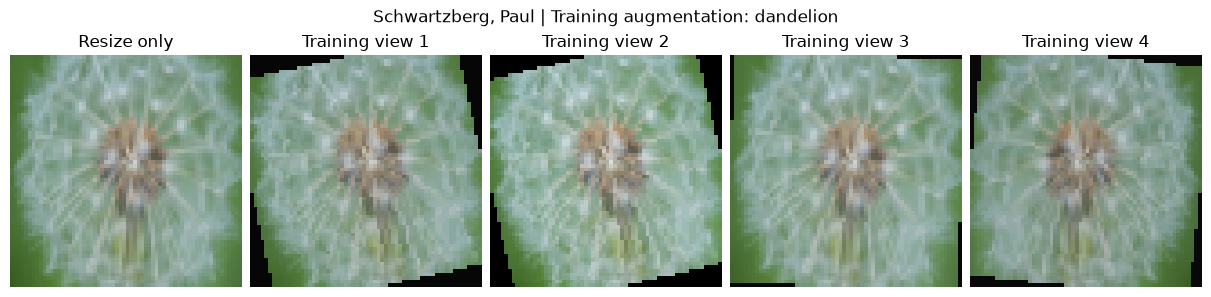

In [10]:
# Show four random training views of one image, with the same label.
preview_path, preview_label = flower_records["train"][0]
with Image.open(preview_path) as picture:
    picture = picture.convert("RGB")
    fig, axes = plt.subplots(1, 5, figsize=(12, 3), layout="constrained")
    for index, ax in enumerate(axes):
        shown = (eval_transform if index == 0 else augmented_transform)(picture)
        ax.imshow(shown.permute(1, 2, 0))
        ax.set_title("Resize only" if index == 0 else f"Training view {index}")
        ax.axis("off")
fig.suptitle(f"Schwartzberg, Paul | Training augmentation: {flower_classes[preview_label]}")
fig.savefig(OUTPUT_DIR / "augmentation_examples.png", dpi=120)
plt.show()
# Experiments below reset all seeds after this preview.


### 2.5 Define the original and batch-normalised models

Both variants have convolution widths 16, 32 and 64, followed by a linear head from 4,096 values to 64 and then five class scores. The added layer order is `Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d`.

During training, BatchNorm uses batch statistics and updates running estimates. During evaluation, it uses those saved running estimates. Its learned scale and offset are additional parameters. We keep the original convolution biases to change only the requested layers.

`copy_shared_start` copies the same convolution and linear values into every model. A digest checks that these starting values match. The BatchNorm scale and offset retain their usual initial values of one and zero.

In [11]:
"""Schwartzberg, Paul. BasicCNN variants for CSCI E-89 HW5 Problem 2."""
import hashlib
import torch
from torch import nn

class BasicCNN(nn.Module):
    """The three-block course model, with optional BatchNorm after each Conv2d."""
    def __init__(self, num_classes=5, batch_norm=False, image_size=64):
        super().__init__()
        layers = []
        in_channels = 3
        for out_channels in (16, 32, 64):
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))  # Before ReLU, after every convolution.
            layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
            in_channels = out_channels
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * (image_size // 8) ** 2, 64),
            nn.ReLU(), nn.Linear(64, num_classes),
        )
    def forward(self, images):
        return self.classifier(self.features(images))

def shared_layers(model):
    """Return the convolutions and linear layers, in the same order in both variants."""
    return [layer for layer in model.modules() if isinstance(layer, (nn.Conv2d, nn.Linear))]

def copy_shared_start(model, reference):
    """Give every experiment exactly the same starting convolution and linear weights."""
    for target, source in zip(shared_layers(model), shared_layers(reference), strict=True):
        target.load_state_dict(source.state_dict(), strict=True)

def shared_weight_digest(model):
    """Identify the shared initial weights, excluding the added BatchNorm parameters."""
    digest = hashlib.sha256()
    for layer in shared_layers(model):
        for value in layer.state_dict().values():
            digest.update(value.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


In [12]:
# The only two experimental changes are BatchNorm and training augmentation.
EXPERIMENTS = [
    {"name": "original_no_augmentation", "batch_norm": False, "augmentation": False},
    {"name": "batchnorm_no_augmentation", "batch_norm": True, "augmentation": False},
    {"name": "original_with_augmentation", "batch_norm": False, "augmentation": True},
    {"name": "batchnorm_with_augmentation", "batch_norm": True, "augmentation": True},
]
seed_everything()
reference_model = BasicCNN(len(flower_classes))
INITIAL_DIGEST = shared_weight_digest(reference_model)
example_model = BasicCNN(len(flower_classes), batch_norm=True)
copy_shared_start(example_model, reference_model)
assert shared_weight_digest(example_model) == INITIAL_DIGEST
assert sum(isinstance(layer, nn.BatchNorm2d) for layer in example_model.modules()) == 3
for index, layer in enumerate(example_model.features):
    if isinstance(layer, nn.Conv2d):
        assert isinstance(example_model.features[index + 1], nn.BatchNorm2d)
print(example_model)
print("Shared initial convolution/linear digest:", INITIAL_DIGEST)


BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=64, bias=True)
  

### 2.6 Train four runs and save selected checkpoints

The function resets seeds and the shuffled-loader generator for each condition. Batch order and common starting weights match across runs; augmented views add their own random variation. Cross-entropy compares five raw class scores with integer labels.

Every epoch includes a training pass and a separate validation pass. Whenever validation loss improves, we copy the complete state, including BatchNorm running statistics. We restore that state after 30 epochs and verify that a saved-and-reloaded model returns the same scores. Test images are not read during this selection.

Only selected progress lines are printed here. The JSON histories contain all 30 epochs, and the plots below show them all.

In [13]:
def train_basic_experiment(config):
    """Train one condition, using validation loss to select its checkpoint."""
    seed_everything()
    model = BasicCNN(len(flower_classes), batch_norm=config["batch_norm"]).to(device)
    copy_shared_start(model, reference_model)
    assert shared_weight_digest(model) == INITIAL_DIGEST
    transform = augmented_transform if config["augmentation"] else eval_transform
    dataset = PhotoDataset(flower_records["train"], transform, cache_images=True)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    # Reset stochastic transforms after construction; each run has the same batch order.
    seed_everything()
    history = {key: [] for key in ("train_loss", "val_loss", "train_accuracy", "val_accuracy")}
    best_loss, best_epoch, best_state = float("inf"), None, None
    start = time.perf_counter()
    print("Training:", config["name"], flush=True)
    for epoch in range(1, EPOCHS + 1):
        train = run_epoch(model, loader, device, optimizer)
        validation = run_epoch(model, val_loader, device)
        history["train_loss"].append(train["loss"])
        history["train_accuracy"].append(train["accuracy"])
        history["val_loss"].append(validation["loss"])
        history["val_accuracy"].append(validation["accuracy"])
        if validation["loss"] < best_loss:
            best_loss, best_epoch = validation["loss"], epoch
            best_state = cpu_state(model)
        # All epochs go to JSON; a short output keeps the submitted notebook readable.
        if epoch == 1 or epoch % 10 == 0:
            print(f"  Epoch {epoch:02d}/{EPOCHS}: train loss {train['loss']:.4f}, acc {train['accuracy']:.2%}; "
                  f"validation loss {validation['loss']:.4f}, acc {validation['accuracy']:.2%}", flush=True)
    model.load_state_dict(best_state, strict=True)
    selected = run_epoch(model, val_loader, device)
    checkpoint = {
        "author": "Schwartzberg, Paul", "state_dict": cpu_state(model), "config": config,
        "class_names": flower_classes, "image_size": IMAGE_SIZE, "best_epoch": best_epoch,
        "seed": SEED, "split_sha256": flower_data["manifest"]["split_sha256"],
        "initial_shared_sha256": INITIAL_DIGEST, "selection_rule": "minimum validation cross-entropy loss",
    }
    checkpoint_path = OUTPUT_DIR / (config["name"] + ".pth")
    torch.save(checkpoint, checkpoint_path)
    # Confirm the saved file restores the selected model's scores, including BN buffers.
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    reloaded = BasicCNN(len(flower_classes), batch_norm=config["batch_norm"]).to(device)
    reloaded.load_state_dict(saved["state_dict"], strict=True)
    model.eval(); reloaded.eval()
    sample = val_dataset[0][0].unsqueeze(0).to(device)
    with torch.no_grad():
        torch.testing.assert_close(model(sample), reloaded(sample), rtol=0, atol=0)
    result = {
        "author": "Schwartzberg, Paul", "config": config, "seed": SEED,
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "initial_shared_sha256": INITIAL_DIGEST, "split_sha256": saved["split_sha256"],
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch, "selected_validation": selected, "history": history,
        "training_seconds": time.perf_counter() - start, "reload_verified": True,
    }
    write_json(OUTPUT_DIR / (config["name"] + "_metrics.json"), result)
    print(f"  Restored epoch {best_epoch}; validation loss {selected['loss']:.4f}; reload verified.", flush=True)
    return result

# Train and select all four checkpoints before examining any test results.
p2_results = [train_basic_experiment(config) for config in EXPERIMENTS]


Training: original_no_augmentation


  Epoch 01/30: train loss 1.4530, acc 33.36%; validation loss 1.2773, acc 45.64%


  Epoch 10/30: train loss 0.8207, acc 67.11%; validation loss 0.9411, acc 63.09%


  Epoch 20/30: train loss 0.5518, acc 78.67%; validation loss 1.0060, acc 64.91%


  Epoch 30/30: train loss 0.2431, acc 91.44%; validation loss 1.2124, acc 67.45%


...

  Epoch 01/30: train loss 1.3198, acc 47.49%; validation loss 1.3483, acc 40.18%


  Epoch 10/30: train loss 0.6715, acc 74.15%; validation loss 0.7665, acc 71.64%


  Epoch 20/30: train loss 0.4664, acc 82.41%; validation loss 0.7371, acc 71.27%


  Epoch 30/30: train loss 0.3838, acc 86.26%; validation loss 0.7824, acc 73.45%


  Restored epoch 23; validation loss 0.6909; reload verified.


### 2.7 Compare complete test-set results

All four checkpoints have now been selected. This cell uses all 551 test images for each model, with fixed preprocessing, evaluation mode and no gradient calculation. It saves accuracy, macro precision, balanced accuracy, per-class precision/recall/F1, loss and each image's prediction. No test score is used to change an experiment or checkpoint.

In [14]:
# Evaluate every selected checkpoint on the same complete test set.
for result in p2_results:
    config = result["config"]
    checkpoint_path = OUTPUT_DIR / (config["name"] + ".pth")
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = BasicCNN(len(flower_classes), batch_norm=config["batch_norm"]).to(device)
    model.load_state_dict(checkpoint["state_dict"], strict=True)
    test = evaluate_classifier(model, test_loader, device, flower_classes)
    assert test["count"] == 551 == flower_data["manifest"]["counts"]["test"]
    result["test"] = test
    write_json(OUTPUT_DIR / (config["name"] + "_metrics.json"), result)
    print(config["name"], f"test accuracy {test['accuracy']:.2%}; macro precision {test['macro_precision']:.2%}; "
          f"loss {test['loss']:.4f}; images {test['count']}")
write_json(OUTPUT_DIR / "comparison.json", {"author": "Schwartzberg, Paul", "experiments": p2_results})

# Accuracy is the fraction correct; macro precision gives each class equal weight.
rows = ["| Condition | Selected epoch | Validation loss | Test accuracy | Test macro precision |",
        "|---|---:|---:|---:|---:|"]
for result in p2_results:
    rows.append(f"| {result['config']['name']} | {result['best_epoch']} | {result['selected_validation']['loss']:.4f} "
                f"| {result['test']['accuracy']:.2%} | {result['test']['macro_precision']:.2%} |")
display(Markdown("\n".join(rows)))


original_no_augmentation test accuracy 64.61%; macro precision 64.35%; loss 0.8797; images 551


batchnorm_no_augmentation test accuracy 70.96%; macro precision 70.98%; loss 0.8040; images 551


original_with_augmentation test accuracy 68.60%; macro precision 68.99%; loss 0.8101; images 551


batchnorm_with_augmentation test accuracy 74.77%; macro precision 74.38%; loss 0.7301; images 551


| Condition | Selected epoch | Validation loss | Test accuracy | Test macro precision |
|---|---:|---:|---:|---:|
| original_no_augmentation | 11 | 0.9146 | 64.61% | 64.35% |
| batchnorm_no_augmentation | 9 | 0.7678 | 70.96% | 70.98% |
| original_with_augmentation | 24 | 0.8238 | 68.60% | 68.99% |
| batchnorm_with_augmentation | 23 | 0.6909 | 74.77% | 74.38% |

### 2.8 Learning curves and confusion matrices

The training and validation histories show whether better training fit carries over to held-out images. The dashed line marks the selected checkpoint. A gap or rising validation loss can indicate overfitting; BatchNorm and augmentation do not guarantee that it disappears. Each confusion matrix includes the same full test set.

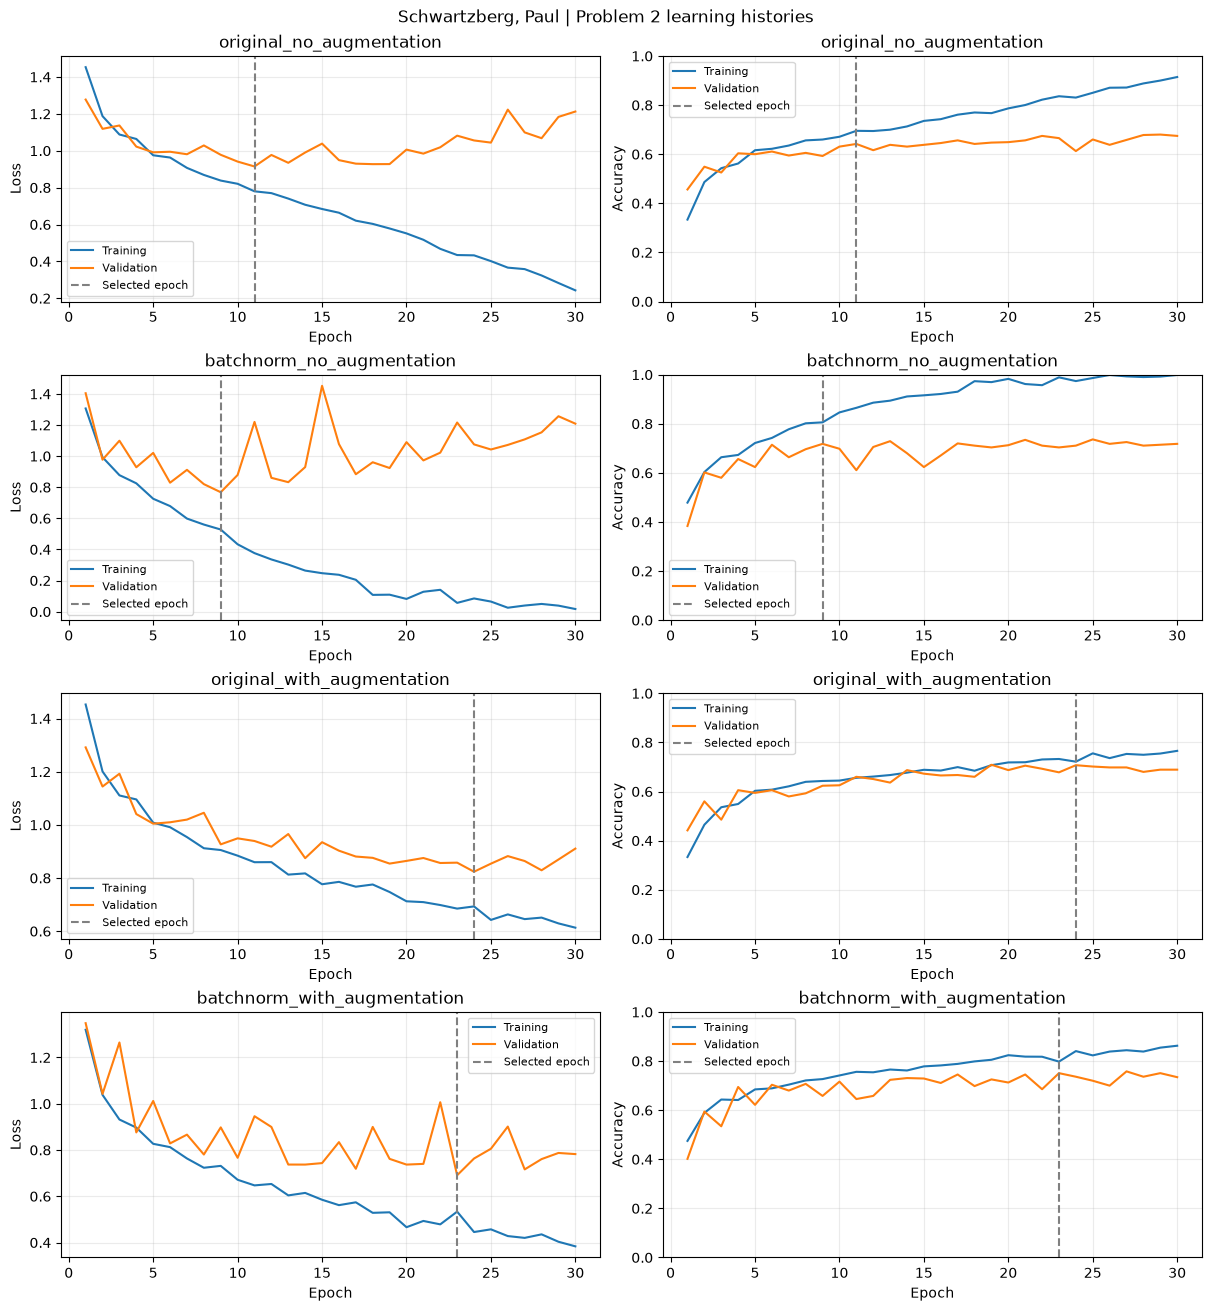

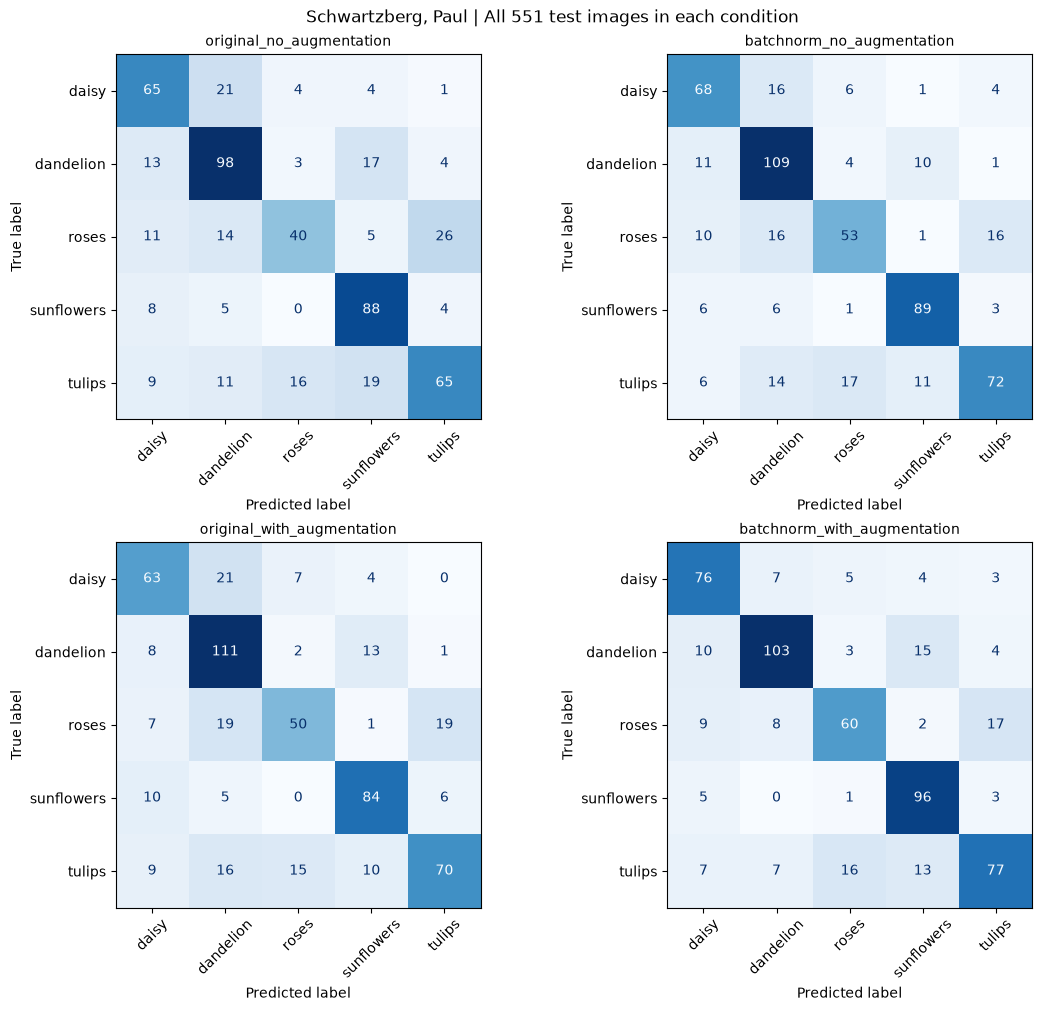

In [15]:
# Show every run's learning history and selected validation checkpoint.
fig, axes = plt.subplots(4, 2, figsize=(12, 13), layout="constrained")
for row, result in enumerate(p2_results):
    epochs = np.arange(1, len(result["history"]["train_loss"]) + 1)
    for col, metric in enumerate(("loss", "accuracy")):
        ax = axes[row, col]
        ax.plot(epochs, result["history"]["train_" + metric], label="Training")
        ax.plot(epochs, result["history"]["val_" + metric], label="Validation")
        ax.axvline(result["best_epoch"], color="grey", linestyle="--", label="Selected epoch")
        ax.set(title=result["config"]["name"], xlabel="Epoch", ylabel=metric.capitalize())
        ax.grid(alpha=0.25); ax.legend(fontsize=8)
        if metric == "accuracy": ax.set_ylim(0, 1)
fig.suptitle("Schwartzberg, Paul | Problem 2 learning histories")
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=120)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 10), layout="constrained")
for ax, result in zip(axes.flat, p2_results):
    ConfusionMatrixDisplay(np.array(result["test"]["confusion_matrix"]), display_labels=flower_classes).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(result["config"]["name"], fontsize=10)
fig.suptitle("Schwartzberg, Paul | All 551 test images in each condition")
fig.savefig(OUTPUT_DIR / "test_confusion_matrices.png", dpi=120)
plt.show()


### 2.9 Interpretation

| Condition | Selected epoch | Validation loss | Test correct / 551 | Test accuracy | Test macro precision |
|---|---:|---:|---:|---:|---:|
| Original, no augmentation | 11 | 0.9146 | 356 / 551 | 64.61% | 64.35% |
| BatchNorm, no augmentation | 9 | 0.7678 | 391 / 551 | 70.96% | 70.98% |
| Original, with augmentation | 24 | 0.8238 | 378 / 551 | 68.60% | 68.99% |
| BatchNorm, with augmentation | 23 | 0.6909 | 412 / 551 | 74.77% | 74.38% |

Adding BatchNorm increased test accuracy by 6.35 percentage points without augmentation and 6.17 points with augmentation. Adding augmentation increased accuracy by 3.99 points in the original model and 3.81 points in the BatchNorm model. The combined condition had the highest test accuracy and macro precision in these four fixed runs. Its test accuracy exceeded the original unaugmented model by 10.16 points.

**Training fit and overfitting.** Without augmentation, the original model reached 91.44% training accuracy at epoch 30, while the BatchNorm model reached 99.88%. Their final validation losses were both about 1.21, higher than their selected losses of 0.9146 and 0.7678. We therefore restored epochs 11 and 9. BatchNorm improved the selected held-out result, but did not prevent later overfitting.

Augmentation reduced the training/validation gap in the learning curves and moved the selected checkpoints later, to epochs 24 and 23. The combined condition ended with 86.26% training accuracy and 73.45% validation accuracy. Its lowest validation loss was 0.6909 at epoch 23; the final loss rose to 0.7824. We restored epoch 23 rather than the final weights. Training accuracy here is measured during training on the condition's current views; augmented training views are harder than the fixed validation images.

**Remaining errors.** In the combined condition, sunflowers had the highest test recall, 91.43%; roses had the lowest, 62.50%. Seventeen roses were predicted as tulips. Improvements were not uniform across classes: dandelion recall was 76.30% in the combined condition, compared with 80.74% for BatchNorm alone. The confusion matrices show those trade-offs.

These experiments use one seed, one split and one 30-epoch budget. We have not measured variation across repeated seeds. All four conditions were fixed before test evaluation; no test result changed an experiment or checkpoint. The complete test set, rather than a small gallery, supplies every reported test metric.

**Problem 2 is complete.** All four runs trained, selected checkpoints by validation loss, passed saved-weight reload checks, and evaluated every one of the 551 test images. Exact starting-weight and split digests, full histories, per-class reports, predictions and plots are saved in `outputs/problem2/`.


<a id="problem-3"></a>

## Problem 3: VGG16 flower classification

I adapt the lecture notebook `3_FineTune_VGG16_PyTorch_Cat_Dog.ipynb`
to the five flower classes. Stage 1 trains a new classifier while all
ImageNet convolutional weights are frozen. Stage 2 starts from the selected
stage-1 weights and fine-tunes only VGG16's final convolutional block and
the classifier. Both selected stages are evaluated on the complete test set.

Run all cells from top to bottom in the `cscie89` kernel. A fresh run downloads
the official VGG16 weights (about 528 MB) once and then trains both stages.
The CPU run uses four threads. Outputs and checkpoints are saved beneath
`outputs/problem3`; these checkpoints are also used by Problem 4.

### 3.1 Settings and the shared flower split

The dataset contains 3,670 photographs, divided into 2,569 training, 550 validation and 551 test images. The split is stratified by flower type and fixed by seed 42. Problem 2 uses this same split.

The shared helpers in Section 2.1 open photographs, record the exact split, set random seeds, and measure a complete pass through a loader. `run_epoch` uses integer class labels and `CrossEntropyLoss`, and updates weights only when an optimiser is supplied.


In [16]:
from pathlib import Path
import time
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Reuse the shared data, training and evaluation helpers defined in Problem 2.


"""The VGG16 flower architecture and checkpoint loader for HW5.

Author: Schwartzberg, Paul.
The original ImageNet classifier is replaced with a five-class flower head.
"""
from pathlib import Path

import torch
from torch import nn
from torchvision import models


class VGGFlowerCNN(nn.Module):
    """VGG16 features followed by a small flower classifier."""

    def __init__(self, num_classes=5, image_size=150, pretrained=False):
        super().__init__()
        weights = models.VGG16_Weights.DEFAULT if pretrained else None
        original = models.vgg16(weights=weights)
        self.features = original.features
        del original  # Release the large ImageNet classifier.
        self.image_size = image_size
        # Five 2-by-2 pools: 150 -> 75 -> 37 -> 18 -> 9 -> 4.
        self.flattened_features = 512 * (image_size // 32) ** 2
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.flattened_features, 256),
            nn.ReLU(inplace=False),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


def load_vgg_checkpoint(path, device="cpu"):
    """Rebuild the architecture without downloading ImageNet weights."""
    checkpoint = torch.load(Path(path), map_location="cpu", weights_only=True)
    model = VGGFlowerCNN(
        num_classes=len(checkpoint["class_names"]),
        image_size=checkpoint["image_size"], pretrained=False,
    )
    if model.flattened_features != checkpoint["flattened_features"]:
        raise ValueError("The saved feature size does not match the architecture.")
    model.load_state_dict(checkpoint["state_dict"], strict=True)
    model.to(device).eval()
    return model, checkpoint


IMAGE_SIZE, BATCH_SIZE = 150, 20
INITIAL_EPOCHS, FINETUNE_EPOCHS = 5, 3
INITIAL_LR, FINETUNE_LR = 2e-5, 1e-5
PATIENCE = 3
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
seed_everything(SEED)
torch.set_num_threads(4)
device = choose_device()
torch.hub.set_dir(str(ROOT / "data" / "torch_hub"))
output_dir = ROOT / "outputs" / "problem3"
output_dir.mkdir(parents=True, exist_ok=True)
flower_data = prepare_flower_data()
class_names = flower_data["class_names"]
split_digest = flower_data["manifest"]["split_sha256"]
print("Device:", device)
print("Class names:", class_names)
print("Split counts:", flower_data["manifest"]["counts"])
print("Split SHA-256:", split_digest)

Device: cpu
Class names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Split counts: {'train': 2569, 'validation': 550, 'test': 551}
Split SHA-256: c9ec6f34c9228118659de17e92cebce224c61aafdb8dd28674bb17af648c4875


### 3.2 Prepare RGB images for ImageNet weights
Training images are resized to 150 by 150 pixels, randomly flipped left to
right and rotated by up to 10 degrees. The random choices are sampled anew
on each visit to an image. Validation and test images have no random changes.
`ToTensor` scales pixel values into [0, 1]; ImageNet normalization subtracts
each channel's mean and divides by its standard deviation. Labels remain
integers from 0 to 4. Only the training loader shuffles images.

In [17]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Cache original RGB pixels only; augmentation still changes on each visit.
train_data = PhotoDataset(flower_data["records"]["train"], train_transform, cache_images=True)
validation_data = PhotoDataset(flower_data["records"]["validation"], eval_transform, cache_images=True)
test_data = PhotoDataset(flower_data["records"]["test"], eval_transform, cache_images=True)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, num_workers=0)
assert len(train_data) + len(validation_data) + len(test_data) == 3670
print("Image tensor shape:", tuple(train_data[0][0].shape), "| Label:", train_data[0][1])

Image tensor shape: (3, 150, 150) | Label: 1


### 3.3 Keep VGG16 features and replace its classifier
The architecture is defined in this notebook. The same definition is saved
in `hw5_vgg.py` for reuse by the standalone script and Problem 4.
`VGGFlowerCNN` retains torchvision's VGG16 `.features`, removes its large
1,000-class ImageNet classifier, and defines the new head shown below.

```python
self.features = original_vgg16.features
self.classifier = nn.Sequential(
    nn.Flatten(),
    nn.Linear(8192, 256),
    nn.ReLU(inplace=False),
    nn.Dropout(0.5),
    nn.Linear(256, 5),
)
```
Five pooling operations reduce 150 -> 75 -> 37 -> 18 -> 9 -> 4 pixels.
The final 512 channels each contain 4 by 4 values: 8,192 values per image.
The new head produces five raw class scores. `CrossEntropyLoss` accepts
these scores directly; softmax is used later to show probability estimates.
Dropout is active during training and disabled during evaluation.

In [18]:
model = VGGFlowerCNN(num_classes=len(class_names), image_size=IMAGE_SIZE,
                     pretrained=True).to(device)
for parameter in model.features.parameters():
    parameter.requires_grad = False
with torch.no_grad():
    feature_shape = model.features(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)).shape
assert tuple(feature_shape) == (1, 512, 4, 4)
assert model.flattened_features == 8192
print("Convolution output:", tuple(feature_shape))
print("New classifier:", model.classifier)
print("Total parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Stage-1 trainable parameters:", sum(parameter.numel() for parameter in model.parameters()
                                             if parameter.requires_grad))
original_feature_weights = cpu_state(model.features)

Convolution output: (1, 512, 4, 4)
New classifier: Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=8192, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=256, out_features=5, bias=True)
)
Total parameters: 16813381
Stage-1 trainable parameters: 2098693


### 3.4 Train with validation loss and preserve the best checkpoint
This follows the lecture's settings: RMSprop with alpha 0.9 and epsilon
1e-7, at most five initial epochs and three fine-tuning epochs, patience
three. Each stage creates a new optimizer containing only trainable weights.
The incoming model is evaluated before the first update and is an epoch-0
candidate. This lets stage 2 retain its stage-1 input if fine-tuning fails
to improve validation loss. A saved copy prevents subsequent updates from
changing the best weights. Test images play no part in this selection.

In [19]:
def fit_vgg(model, epochs, learning_rate, stage_name):
    """Train one stage and restore its lowest-validation-loss weights."""
    started = time.perf_counter()
    optimizer = torch.optim.RMSprop(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=learning_rate, alpha=0.9, eps=1e-7,
    )
    incoming = run_epoch(model, validation_loader, device)
    best_loss, best_epoch, waiting = incoming["loss"], 0, 0
    best_weights = cpu_state(model)
    history = {"train_loss": [], "validation_loss": [],
               "train_accuracy": [], "validation_accuracy": [], "epoch_seconds": []}
    print(f"{stage_name} incoming | Validation: {incoming['accuracy']:.2%}"
          f" | Loss: {incoming['loss']:.4f}", flush=True)
    for epoch in range(1, epochs + 1):
        epoch_started = time.perf_counter()
        train_result = run_epoch(model, train_loader, device, optimizer)
        validation_result = run_epoch(model, validation_loader, device)
        history["train_loss"].append(train_result["loss"])
        history["validation_loss"].append(validation_result["loss"])
        history["train_accuracy"].append(train_result["accuracy"])
        history["validation_accuracy"].append(validation_result["accuracy"])
        history["epoch_seconds"].append(time.perf_counter() - epoch_started)
        if validation_result["loss"] < best_loss:
            best_loss = validation_result["loss"]
            best_weights = cpu_state(model)
            best_epoch, waiting = epoch, 0
        else:
            waiting += 1
        print(f"{stage_name} {epoch}/{epochs} | Train: {train_result['accuracy']:.2%}"
              f" | Validation: {validation_result['accuracy']:.2%}"
              f" | Val loss: {validation_result['loss']:.4f}"
              f" | Seconds: {history['epoch_seconds'][-1]:.1f}", flush=True)
        # Persist progress as well as the final result; this does not select on test data.
        write_json(output_dir / (stage_name + "_progress.json"), {
            "best_epoch": best_epoch, "best_validation_loss": best_loss, "history": history,
        })
        if waiting >= PATIENCE:
            print("Early stopping after three epochs without validation-loss improvement.", flush=True)
            break
    model.load_state_dict(best_weights)
    selected = run_epoch(model, validation_loader, device)
    print(f"{stage_name}: restored epoch {best_epoch}"
          f" | Validation: {selected['accuracy']:.2%} | Loss: {selected['loss']:.4f}", flush=True)
    return {"stage": stage_name, "learning_rate": learning_rate, "maximum_epochs": epochs,
            "best_epoch": best_epoch, "incoming_validation": incoming,
            "selected_validation": selected, "history": history,
            "training_seconds": time.perf_counter() - started}


def save_vgg_stage(model, result, filename):
    """Save learned state together with architecture and preprocessing details."""
    checkpoint = {
        "author": "Schwartzberg, Paul", "state_dict": cpu_state(model),
        "class_names": class_names, "image_size": IMAGE_SIZE, "mean": MEAN, "std": STD,
        "flattened_features": model.flattened_features, "stage": result["stage"],
        "best_epoch": result["best_epoch"], "split_sha256": split_digest,
        "pretrained_source": "torchvision VGG16_Weights.IMAGENET1K_V1",
        "selection_rule": "Lowest validation loss; incoming weights included as epoch 0",
        "settings": {"batch_size": BATCH_SIZE, "learning_rate": result["learning_rate"],
                     "optimizer": "RMSprop", "alpha": 0.9, "eps": 1e-7, "patience": PATIENCE},
    }
    torch.save(checkpoint, output_dir / filename)
    write_json(output_dir / (result["stage"] + "_training.json"), result)
    print("Saved:", filename, flush=True)

### 3.5 Stage 1: train the new classifier
All 13 VGG16 convolutions are frozen. Only the two new linear layers learn.
The check compares every convolutional weight and bias against the original
ImageNet values after training. The saved checkpoint contains the restored
best epoch, which can differ from the last epoch printed.

In [20]:
stage1_result = fit_vgg(model, INITIAL_EPOCHS, INITIAL_LR, "stage1")
for name, value in model.features.state_dict().items():
    torch.testing.assert_close(value.detach().cpu(), original_feature_weights[name], rtol=0, atol=0)
save_vgg_stage(model, stage1_result, "stage1_vgg16.pth")
print("Stage 1 check: all pretrained convolutional weights stayed unchanged.")
del original_feature_weights

stage1 incoming | Validation: 17.82% | Loss: 1.6610


stage1 1/5 | Train: 57.84% | Validation: 70.91% | Val loss: 0.8947 | Seconds: 137.7


stage1 2/5 | Train: 75.67% | Validation: 75.45% | Val loss: 0.6862 | Seconds: 136.0


stage1 3/5 | Train: 79.72% | Validation: 76.73% | Val loss: 0.6117 | Seconds: 142.7


stage1 4/5 | Train: 83.07% | Validation: 80.73% | Val loss: 0.5527 | Seconds: 116.1


stage1 5/5 | Train: 84.00% | Validation: 81.27% | Val loss: 0.5321 | Seconds: 118.8


stage1: restored epoch 5 | Validation: 81.27% | Loss: 0.5321


Saved: stage1_vgg16.pth


Stage 1 check: all pretrained convolutional weights stayed unchanged.


### 3.6 Stage 2: fine-tune block 5 and the classifier
`features[24:]` begins at VGG16 block 5, containing convolutions at indices
24, 26 and 28. Blocks 1-4 remain frozen. We continue with the selected
stage-1 model and lower the learning rate from 2e-5 to 1e-5. A fresh optimizer
includes the newly trainable parameters. The check below verifies that the
earlier blocks remain exactly unchanged.

In [21]:
frozen_prefix_weights = cpu_state(model.features[:24])
for parameter in model.features[24:].parameters():
    parameter.requires_grad = True
print("Trainable convolution indices:", [index for index, layer in enumerate(model.features)
                                          if isinstance(layer, nn.Conv2d) and layer.weight.requires_grad])
print("Stage-2 trainable parameters:", sum(parameter.numel() for parameter in model.parameters()
                                             if parameter.requires_grad))
stage2_result = fit_vgg(model, FINETUNE_EPOCHS, FINETUNE_LR, "stage2")
for name, value in model.features[:24].state_dict().items():
    torch.testing.assert_close(value.detach().cpu(), frozen_prefix_weights[name], rtol=0, atol=0)
save_vgg_stage(model, stage2_result, "stage2_vgg16.pth")
print("Stage 2 check: VGG16 blocks 1-4 stayed unchanged.")
del frozen_prefix_weights

Trainable convolution indices: [24, 26, 28]
Stage-2 trainable parameters: 9178117


stage2 incoming | Validation: 81.27% | Loss: 0.5321


stage2 1/3 | Train: 86.45% | Validation: 82.55% | Val loss: 0.4766 | Seconds: 156.4


stage2 2/3 | Train: 89.68% | Validation: 83.45% | Val loss: 0.4541 | Seconds: 155.9


stage2 3/3 | Train: 90.85% | Validation: 84.00% | Val loss: 0.4404 | Seconds: 156.0


stage2: restored epoch 3 | Validation: 84.00% | Loss: 0.4404


Saved: stage2_vgg16.pth


Stage 2 check: VGG16 blocks 1-4 stayed unchanged.


### 3.7 Plot the training and validation histories
Each stage has its own epoch numbers. Dashed vertical lines identify the
selected epoch when it is greater than zero. Training metrics are measured
during updates, with augmentation and dropout; validation uses fixed
preprocessing and evaluation mode. Their difference is therefore not a
pure measure of overfitting. The test set is still unused at this point.

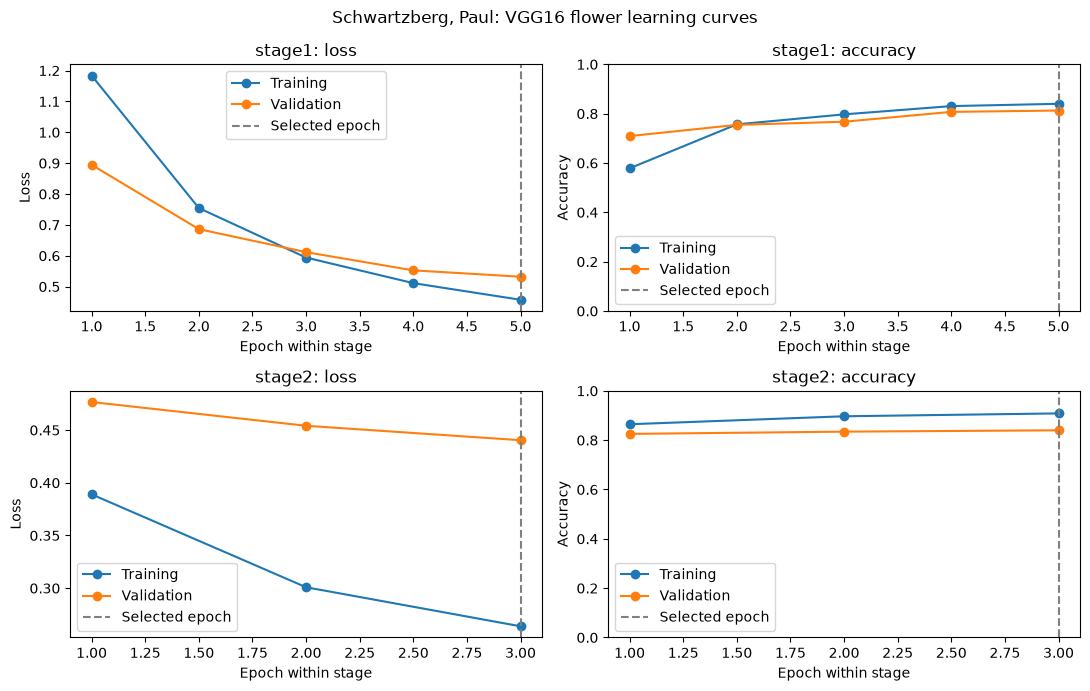

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, result in enumerate([stage1_result, stage2_result]):
    history = result["history"]
    epochs = range(1, len(history["train_loss"]) + 1)
    for column, metric in enumerate(["loss", "accuracy"]):
        ax = axes[row, column]
        ax.plot(epochs, history["train_" + metric], marker="o", label="Training")
        ax.plot(epochs, history["validation_" + metric], marker="o", label="Validation")
        if result["best_epoch"] > 0:
            ax.axvline(result["best_epoch"], color="gray", linestyle="--", label="Selected epoch")
        ax.set(xlabel="Epoch within stage", ylabel=metric.capitalize(),
               title=result["stage"] + ": " + metric)
        ax.legend()
        if metric == "accuracy":
            ax.set_ylim(0, 1)
fig.suptitle("Schwartzberg, Paul: VGG16 flower learning curves")
fig.tight_layout()
fig.savefig(output_dir / "learning_curves.png", dpi=140)
plt.show()

### 3.8 Evaluate both selected stages on all 551 test images
The assignment asks for precision. We report the literal macro precision
(the equal-weight average of the five class precisions), accuracy and each
class's precision, recall and F1. Precision asks how many predictions of a
class are correct; recall asks how many actual members of that class were
found. The confusion matrices place actual labels in rows and predictions
in columns. Both models have already been selected using validation loss.

Reloading each checkpoint verifies that the saved state reproduces its
predictions. The full test set is evaluated once for each selected stage.
We do not change settings after seeing these results.

stage1 | Entire test set: 551 images | Accuracy: 87.11% | Macro precision: 87.49% | Loss: 0.4112
              precision    recall  f1-score   support

       daisy      0.878     0.905     0.891        95
   dandelion      0.872     0.911     0.891       135
       roses      0.895     0.802     0.846        96
  sunflowers      0.906     0.829     0.866       105
      tulips      0.823     0.892     0.856       120

    accuracy                          0.871       551
   macro avg      0.875     0.868     0.870       551
weighted avg      0.873     0.871     0.871       551



stage2 | Entire test set: 551 images | Accuracy: 89.29% | Macro precision: 89.87% | Loss: 0.2831
              precision    recall  f1-score   support

       daisy      0.887     0.905     0.896        95
   dandelion      0.928     0.956     0.942       135
       roses      0.925     0.771     0.841        96
  sunflowers      0.948     0.867     0.905       105
      tulips      0.806     0.933     0.865       120

    accuracy                          0.893       551
   macro avg      0.899     0.886     0.890       551
weighted avg      0.898     0.893     0.893       551



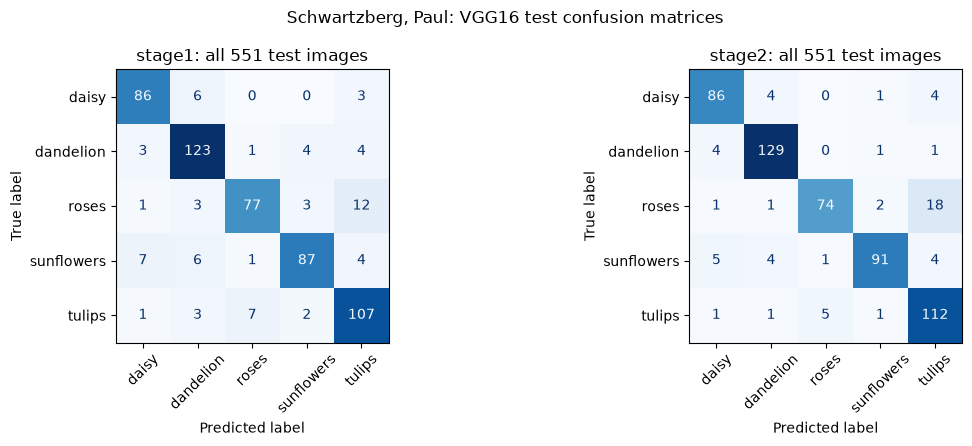

In [23]:
test_results = {}
stage_models = {}
sample_for_reload_check = test_data[0][0].unsqueeze(0).to(device)
for stage, filename in [("stage1", "stage1_vgg16.pth"), ("stage2", "stage2_vgg16.pth")]:
    restored, checkpoint = load_vgg_checkpoint(output_dir / filename, device)
    assert checkpoint["split_sha256"] == split_digest
    # Check the reconstruction against the exact saved tensors and a second reload.
    for name, value in restored.state_dict().items():
        torch.testing.assert_close(value.detach().cpu(), checkpoint["state_dict"][name], rtol=0, atol=0)
    restored.eval()
    with torch.no_grad():
        expected_scores = restored(sample_for_reload_check)
        verified, _ = load_vgg_checkpoint(output_dir / filename, device)
        torch.testing.assert_close(verified(sample_for_reload_check), expected_scores, rtol=0, atol=0)
    del verified
    result = evaluate_classifier(restored, test_loader, device, class_names)
    assert result["count"] == 551
    test_results[stage] = result
    stage_models[stage] = restored
    write_json(output_dir / (stage + "_test_metrics.json"), result)
    print(f"{stage} | Entire test set: {result['count']} images"
          f" | Accuracy: {result['accuracy']:.2%}"
          f" | Macro precision: {result['macro_precision']:.2%}"
          f" | Loss: {result['loss']:.4f}")
    print(classification_report(result["true_labels"], result["predicted_labels"],
                                labels=list(range(5)), target_names=class_names,
                                digits=3, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, stage in zip(axes, ["stage1", "stage2"]):
    display = ConfusionMatrixDisplay(test_results[stage]["confusion_matrix"], display_labels=class_names)
    # Convert the saved list to the array expected by matplotlib's matrix display.
    import numpy as np
    display.confusion_matrix = np.asarray(display.confusion_matrix)
    display.plot(ax=ax, colorbar=False, cmap="Blues", xticks_rotation=45)
    ax.set_title(stage + ": all 551 test images")
fig.suptitle("Schwartzberg, Paul: VGG16 test confusion matrices")
fig.tight_layout()
fig.savefig(output_dir / "test_confusion_matrices.png", dpi=140)
plt.show()

### 3.9 Predict one fixed test image from every class
For each class we use its first test filename in sorted order, chosen without
checking predictions. Both stages see the same five images. The displayed
score is the softmax estimate for the predicted class, not a guarantee of
correctness. This small gallery illustrates inference; the overall results
above use all 551 test images.

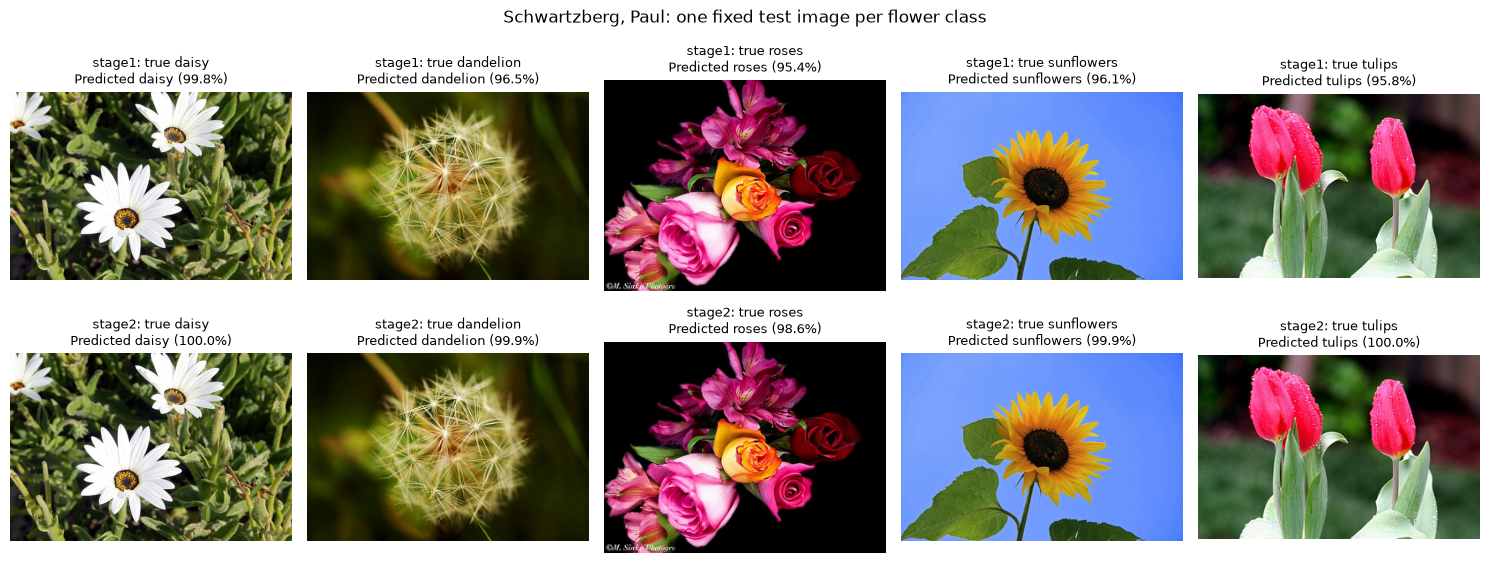

Stage 2 minus stage 1 test accuracy: +2.18 percentage points
Stage 2 minus stage 1 macro precision: +2.38 percentage points
Both checkpoints reloaded successfully. The reported results include every test image.
Saved reports, plots and both stages to: C:\Users\schwa\Documents\H_DCE\CSCI E-89 Deep Learning\Week5\Assignment\dec05c\outputs\problem3


In [24]:
gallery_records = [sorted((path, label) for path, label in flower_data["records"]["test"]
                           if label == class_index)[0] for class_index in range(5)]
gallery_results = []
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for column, (path, actual_label) in enumerate(gallery_records):
    with Image.open(path) as picture:
        original = picture.convert("RGB")
        tensor = eval_transform(original).unsqueeze(0).to(device)
        for row, stage in enumerate(["stage1", "stage2"]):
            with torch.no_grad():
                probabilities = stage_models[stage](tensor).softmax(1)[0]
            predicted = int(probabilities.argmax())
            score = float(probabilities[predicted])
            axes[row, column].imshow(original)
            axes[row, column].set_title(f"{stage}: true {class_names[actual_label]}\n"
                                         f"Predicted {class_names[predicted]} ({score:.1%})", fontsize=9)
            axes[row, column].axis("off")
            gallery_results.append({"stage": stage, "path": path.relative_to(flower_data["root"]).as_posix(),
                                    "true_class": class_names[actual_label],
                                    "predicted_class": class_names[predicted], "score": score})
fig.suptitle("Schwartzberg, Paul: one fixed test image per flower class")
fig.tight_layout()
fig.savefig(output_dir / "five_class_predictions.png", dpi=140)
plt.show()
write_json(output_dir / "five_class_predictions.json", gallery_results)
comparison = {
    "author": "Schwartzberg, Paul", "class_names": class_names, "split_sha256": split_digest,
    "selection_rule": "Lowest validation loss, including the incoming epoch-0 candidate",
    "stage1": {"training": stage1_result, "test": test_results["stage1"]},
    "stage2": {"training": stage2_result, "test": test_results["stage2"]},
}
write_json(output_dir / "comparison.json", comparison)
accuracy_change = test_results["stage2"]["accuracy"] - test_results["stage1"]["accuracy"]
precision_change = test_results["stage2"]["macro_precision"] - test_results["stage1"]["macro_precision"]
print(f"Stage 2 minus stage 1 test accuracy: {100 * accuracy_change:+.2f} percentage points")
print(f"Stage 2 minus stage 1 macro precision: {100 * precision_change:+.2f} percentage points")
print("Both checkpoints reloaded successfully. The reported results include every test image.")
print("Saved reports, plots and both stages to:", output_dir)

### 3.10 Interpretation

In this recorded run, stage 1 selected epoch 5 and stage 2 selected epoch 3 by their lowest validation loss. Fine-tuning reduced the selected validation loss from **0.5321 to 0.4404**, while validation accuracy rose from **81.27% to 84.00%**.

| Selected stage | Test images | Correct predictions | Test accuracy | Macro precision | Test loss |
|---|---:|---:|---:|---:|---:|
| Stage 1: frozen ImageNet base | 551 | 480 | 87.11% | 87.49% | 0.4112 |
| Stage 2: fine-tune block 5 and head | 551 | 492 | 89.29% | 89.87% | 0.2831 |

Stage 2 made **12 more correct predictions**, increasing accuracy by **2.18 percentage points** and macro precision by **2.38 percentage points**. Fine-tuning helped overall in this split, though it did not improve every class. Rose recall fell from **80.2% to 77.1%**: 18 roses were predicted as tulips in stage 2, compared with 12 in stage 1. Tulip precision also fell from **82.3% to 80.6%**. Those errors remain in the full reports and confusion matrices.

Both stages correctly identified the five fixed gallery images, one from each class. These examples were chosen by sorted filename before examining predictions. Their success is illustrative; the overall scores above use every test image. A softmax estimate rounded to 100.0% still does not guarantee correctness.

Training accuracy rose faster than validation accuracy during fine-tuning, widening the gap. Validation loss nevertheless improved in all three fine-tuning epochs. I kept the lecture's small epoch budget and selected checkpoints by validation loss. Test results were not used to alter settings or select epochs. These are results from one fixed split and seed, not a claim that every run will reproduce the same scores.

Both saved checkpoints passed exact state and prediction checks after reloading. Stage 1 preserved every pretrained convolutional parameter; stage 2 preserved blocks 1-4. Problem 4 uses the saved stage-2 checkpoint for Grad-CAM.

<a id="problem-4"></a>

## Problem 4: Grad-CAM for the stage 2 VGG16 model

Problem 4 asks us to adapt the Grad-CAM method from `02_lab5_TL-resnet_xception.ipynb` to the stage 2 model trained in Problem 3. We load that saved VGG16 checkpoint and inspect **one convolutional layer**, `features[28]` (VGG16's last convolution, `conv5_3`). The first daisy photograph in the sorted validation paths is fixed before making a prediction.

This section runs after Problem 3 has saved its stage 2 checkpoint. It uses the same 150 x 150 resize and ImageNet normalisation. It makes predictions and calculates gradients for an explanation.

This section reuses the data helpers from Problem 2 and the VGG16 architecture and checkpoint loader from Problem 3.


### 4.1 Restore the trained stage 2 model

The checkpoint supplies the architecture settings, class order, learned weights and biases, selected epoch, and image preprocessing values. `load_vgg_checkpoint` restores the weights with a strict match. Evaluation mode disables classifier dropout. All parameter gradients are disabled; we will track the input instead.

We save a separate copy of the state so that the final check can detect any change to a parameter or stored buffer. VGG16 normally applies ReLU in place. We switch to the equivalent out-of-place operation so the convolution output remains available to differentiate. Both versions calculate the same values in evaluation mode.

In [25]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch import nn
from torchvision import transforms


seed_everything(42)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")
OUTPUT_DIR = Path("outputs/problem4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = Path("outputs/problem3/stage2_vgg16.pth")
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError("Run Problem 3 first to save its stage 2 checkpoint.")

model, checkpoint = load_vgg_checkpoint(CHECKPOINT_PATH, device=DEVICE)
model.eval()
model.requires_grad_(False)
CLASS_NAMES = checkpoint["class_names"]
IMAGE_SIZE = int(checkpoint["image_size"])
MEAN = checkpoint["mean"]
STD = checkpoint["std"]

# Keep every trained parameter unchanged. Gradients will track the input.
original_state = {
    name: value.detach().cpu().clone()
    for name, value in model.state_dict().items()
}

# VGG uses in-place ReLU by default. Disable that memory optimisation so that
# the last convolution's output remains available to differentiate exactly.
# Evaluation predictions are unchanged: both ReLU forms compute max(0, x).
for layer in model.modules():
    if isinstance(layer, nn.ReLU):
        layer.inplace = False
TARGET_LAYER_INDEX = 28
assert isinstance(model.features[TARGET_LAYER_INDEX], nn.Conv2d)
print("Python:", sys.executable)
print("Loaded:", CHECKPOINT_PATH)
print("Stage:", checkpoint["stage"], "| best epoch:", checkpoint["best_epoch"])
print("Target convolution: features[28] (VGG16 conv5_3)")
print("Classes:", CLASS_NAMES)

Python: C:\Users\schwa\.conda\envs\cscie89\python.exe
Loaded: outputs\problem3\stage2_vgg16.pth
Stage: stage2 | best epoch: 3
Target convolution: features[28] (VGG16 conv5_3)
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


### 4.2 Prepare one fixed validation photograph

The split is exactly the one used for Problems 2 and 3. Selecting the first sorted daisy path makes the example reproducible and prevents selecting an image because its prediction or heat map looks convincing. We retain it even if the prediction is wrong.

`ToTensor` converts the RGB pixels to floating-point values in [0, 1]. Normalisation subtracts the ImageNet mean and divides by the standard deviation separately for red, green and blue. `unsqueeze(0)` adds a batch dimension, making the model input `[1, 3, 150, 150]`. The five softmax values are model probability estimates; the largest one determines the predicted class.

In [26]:
flower_data = prepare_flower_data()
assert flower_data["class_names"] == CLASS_NAMES
DAISY_LABEL = CLASS_NAMES.index("daisy")
daisy_records = sorted(
    (path, label)
    for path, label in flower_data["records"]["validation"]
    if int(label) == DAISY_LABEL
)
assert daisy_records, "No daisy photographs in the saved validation split."
IMAGE_PATH, TRUE_LABEL = daisy_records[0]

# Match the resize and ImageNet normalisation used for the stage 2 model.
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
with Image.open(IMAGE_PATH) as photograph:
    original_image = photograph.convert("RGB").resize(
        (IMAGE_SIZE, IMAGE_SIZE), resample=Image.Resampling.BILINEAR
    )
    image_tensor = image_transform(photograph.convert("RGB"))
display_image = np.asarray(original_image).astype(np.float32) / 255.0
with torch.no_grad():
    expected_logits = model(image_tensor.unsqueeze(0).to(DEVICE))
    probabilities = expected_logits.softmax(dim=1)[0].cpu()
PREDICTED_LABEL = int(probabilities.argmax())
PREDICTED_SCORE = float(probabilities[PREDICTED_LABEL])
print("Fixed validation photograph:", IMAGE_PATH)
print("True flower:", CLASS_NAMES[int(TRUE_LABEL)])
print("Predicted flower:", CLASS_NAMES[PREDICTED_LABEL],
      f"({PREDICTED_SCORE:.1%})")

Fixed validation photograph: C:\Users\schwa\Documents\H_DCE\CSCI E-89 Deep Learning\Week5\Assignment\dec05c\data\flower_photos\daisy\10140303196_b88d3d6cec.jpg
True flower: daisy
Predicted flower: daisy (100.0%)


### 4.3 Calculate Grad-CAM for one convolution

The course method differentiates a chosen **raw class score** with respect to the target layer's activation maps. We use `torch.autograd.grad` to obtain those gradients directly. This avoids accumulating gradients on trained parameters and does not require a backward hook.

For each of the 512 maps, the spatial average of its gradients gives one channel weight. Grad-CAM multiplies each map by its weight, sums the channels, and applies ReLU to retain positive contributions. The primary map targets the predicted class, as in Lab 02. If the prediction is incorrect, a second map targets the true class and is labelled separately.

At this last convolution, the activation tensor is `[1, 512, 9, 9]`: the four preceding pools reduce 150 to 75, 37, 18 and 9. The final pool has not run yet. The remaining layers reduce the maps to 4 x 4 and pass 8,192 values to the classifier. We check that this split forward calculation produces the same scores as the normal forward pass.

The coarse 9 x 9 heat map is enlarged to 150 x 150 for display and scaled to [0, 1]. A zero map remains zero. The enlarged image does not create extra spatial evidence. These relative intensities are not class probabilities.

In [27]:
def generate_gradcam(input_tensor, target_class):
    """Weight the target convolution's maps by class-logit gradients."""
    # A fresh input enables gradients without enabling weight updates.
    tracked_input = input_tensor.detach().unsqueeze(0).to(DEVICE)
    tracked_input.requires_grad_(True)

    # Stop at the final convolution, before its ReLU and the last max pool.
    activation_maps = model.features[:TARGET_LAYER_INDEX + 1](tracked_input)
    later_features = model.features[TARGET_LAYER_INDEX + 1:](activation_maps)
    logits = model.classifier(later_features)
    torch.testing.assert_close(logits.detach(), expected_logits,
                               rtol=1e-5, atol=1e-6)
    assert tuple(activation_maps.shape) == (1, 512, 9, 9)

    # Compute gradients of the chosen raw class score, not of cross-entropy.
    gradients = torch.autograd.grad(
        outputs=logits[0, int(target_class)],
        inputs=activation_maps,
    )[0]
    channel_weights = gradients.mean(dim=(2, 3), keepdim=True)
    coarse_cam = torch.relu(
        (channel_weights * activation_maps).sum(dim=1, keepdim=True)
    ).detach()
    assert tuple(coarse_cam.shape) == (1, 1, 9, 9)
    positive_evidence = bool(coarse_cam.max().item() > 0)

    # Enlargement makes the coarse 9 x 9 map align with the displayed image.
    enlarged_cam = torch.nn.functional.interpolate(
        coarse_cam, size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear", align_corners=False,
    )[0, 0].cpu()
    # Match Lab 02's min-max scaling; an all-zero map stays all zero.
    heatmap = ((enlarged_cam - enlarged_cam.min()) /
               (enlarged_cam.max() - enlarged_cam.min() + 1e-8))
    assert torch.isfinite(heatmap).all()
    return heatmap.numpy(), coarse_cam[0, 0].cpu().numpy(), positive_evidence


# The primary map explains the predicted class, as in Lab 02. If incorrect,
# also inspect the true class without replacing the original photograph.
target_classes = [PREDICTED_LABEL]
if int(TRUE_LABEL) != PREDICTED_LABEL:
    target_classes.append(int(TRUE_LABEL))
cam_results = {}
for target_class in target_classes:
    heatmap, coarse_map, has_positive_evidence = generate_gradcam(
        image_tensor, target_class
    )
    class_name = CLASS_NAMES[target_class]
    cam_results[class_name] = {
        "heatmap": heatmap,
        "coarse_map": coarse_map,
        "positive_evidence": has_positive_evidence,
    }
    np.save(OUTPUT_DIR / f"gradcam_{class_name}.npy", heatmap)
    np.save(OUTPUT_DIR / f"gradcam_{class_name}_coarse.npy", coarse_map)
    print(f"Target {class_name}: coarse map (9, 9); "
          f"positive evidence: {has_positive_evidence}")

Target daisy: coarse map (9, 9); positive evidence: True


### 4.4 Plot the image, heat map and overlay

Each row displays the same resized photograph, the class-specific heat map and their overlay. Red indicates stronger relative positive contribution to the named class score; blue indicates weaker contribution. The colour scale applies to the heat map, not the photograph.

The numerical heat maps, figure and a compact result record are saved in `outputs/problem4`. We then compare every model parameter and buffer with the saved copy using exact equality, confirm that parameter gradients were not accumulated, and check the prediction again.

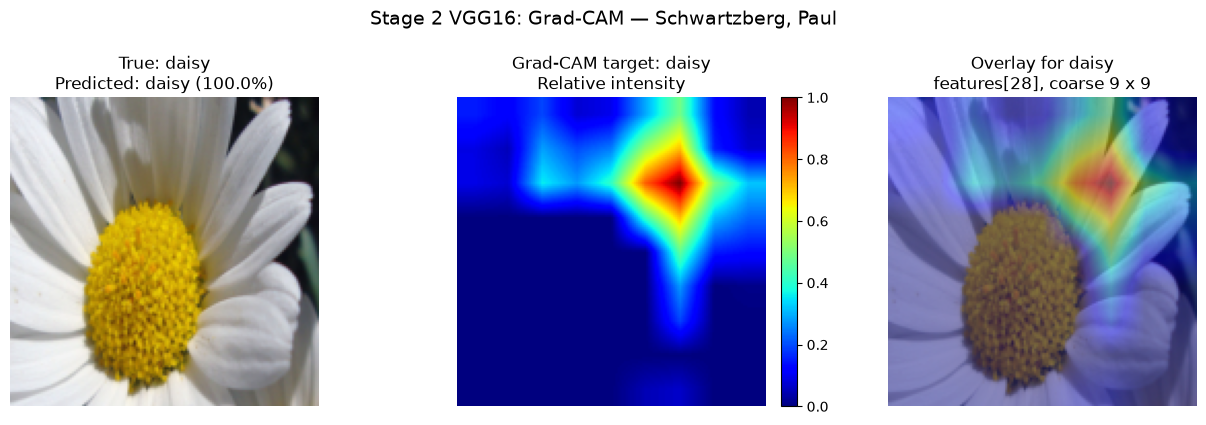

All model weights and buffers are unchanged; no training took place.
Saved the plot, numerical maps and result record to outputs\problem4


In [28]:
fig, axes = plt.subplots(
    len(cam_results), 3, figsize=(13, 4.2 * len(cam_results)), squeeze=False
)
for row, (class_name, result) in enumerate(cam_results.items()):
    heatmap = result["heatmap"]
    axes[row, 0].imshow(display_image)
    axes[row, 0].set_title(
        f"True: {CLASS_NAMES[int(TRUE_LABEL)]}\n"
        f"Predicted: {CLASS_NAMES[PREDICTED_LABEL]} ({PREDICTED_SCORE:.1%})"
    )
    plotted_map = axes[row, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[row, 1].set_title(f"Grad-CAM target: {class_name}\nRelative intensity")
    axes[row, 2].imshow(display_image)
    axes[row, 2].imshow(heatmap, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axes[row, 2].set_title(f"Overlay for {class_name}\nfeatures[28], coarse 9 x 9")
    for axis in axes[row]:
        axis.axis("off")
    fig.colorbar(plotted_map, ax=axes[row, 1], fraction=0.046, pad=0.04)
fig.suptitle("Stage 2 VGG16: Grad-CAM — Schwartzberg, Paul", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(OUTPUT_DIR / "vgg16_gradcam.png", dpi=150, bbox_inches="tight")
plt.show()

# Exact equality detects accidental changes to any stored parameter or buffer.
for name, value in model.state_dict().items():
    torch.testing.assert_close(value.detach().cpu(), original_state[name],
                               rtol=0, atol=0)
assert all(parameter.grad is None for parameter in model.parameters())
with torch.no_grad():
    torch.testing.assert_close(
        model(image_tensor.unsqueeze(0).to(DEVICE)), expected_logits,
        rtol=0, atol=0,
    )
record = {
    "author": "Schwartzberg, Paul",
    "checkpoint": CHECKPOINT_PATH.as_posix(),
    "stage": checkpoint["stage"],
    "best_epoch": int(checkpoint["best_epoch"]),
    "selection": "First sorted daisy path from the saved validation split",
    "image": Path(IMAGE_PATH).relative_to(flower_data["root"]).as_posix(),
    "dataset": "Flower Photos",
    "true_class": CLASS_NAMES[int(TRUE_LABEL)],
    "predicted_class": CLASS_NAMES[PREDICTED_LABEL],
    "predicted_score": PREDICTED_SCORE,
    "probabilities": {
        name: float(value) for name, value in zip(CLASS_NAMES, probabilities)
    },
    "target_layer": "features[28] (VGG16 conv5_3, a single Conv2d)",
    "activation_shape": [1, 512, 9, 9],
    "coarse_heatmap_shape": [9, 9],
    "display_shape": [IMAGE_SIZE, IMAGE_SIZE],
    "cam_targets": {
        name: {"positive_evidence": result["positive_evidence"]}
        for name, result in cam_results.items()
    },
    "weights_unchanged": True,
    "method": "Lab 02 Grad-CAM; direct class-logit gradients via autograd.grad",
}
write_json(OUTPUT_DIR / "gradcam_results.json", record)
print("All model weights and buffers are unchanged; no training took place.")
print("Saved the plot, numerical maps and result record to", OUTPUT_DIR)

### 4.5 Interpretation of the executed result

The stage 2 checkpoint selected **epoch 3**. For the fixed validation photograph `daisy/10140303196_b88d3d6cec.jpg`, the model correctly predicted **daisy**. Its softmax estimate was **99.99846%**, which rounds to 100.0% in the plot. That rounded number is a probability estimate for this image, not a guarantee or a measure of test accuracy. The Grad-CAM target is also daisy, so only one row is needed.

The strongest red region lies over the **upper-right white petals and nearby petal edges**. The large yellow centre is mostly weak blue in this map. The highlighted patch overlaps part of the flower, so the explanation gives some evidence that flower structure contributed to the daisy score. It does not show a complete flower outline or establish that the model used the yellow centre. The broad patch also approaches the neighbouring dark background, so this image alone cannot rule out a contribution from surrounding context.

The target convolution produced 512 maps of size 9 x 9. Grad-CAM combines those maps into one coarse 9 x 9 explanation; enlarging it to 150 x 150 smooths the display without adding detail. The colour scale shows relative positive contributions to the daisy score. It is not a pixel-level segmentation or proof of causal attention. A stronger check would compare further fixed examples or deliberately mask a region, but those experiments are outside this single-image task.

**Checks passed:** All four code cells in Problem 4 ran successfully during the full notebook run in a fresh `cscie89` kernel. The split forward pass matched the normal model prediction, the heat map contained finite values and positive evidence, every parameter and buffer stayed exactly equal to its saved copy, and the final prediction stayed unchanged. The figure, numerical maps and result record are saved in `outputs/problem4`.

Problem 4 is complete: the Lab 02 class-specific Grad-CAM method has been applied to a single target convolution of the trained Problem 3 stage 2 flower model.

## Submission check

The four required problems appear above, with descriptions beside their code and results. The final record checks the split, saved predictions and checkpoint states. The complete submission consists of this notebook and its matching HTML export. The earlier separate notebooks are kept in `individual_problems/` as working records.
